# Descriptive Statistics and Data Summary

Descriptive statistics **summarize and describe** the main features of a dataset.
They give us a quick understanding of:
- **Central tendency**: mean, median, mode
- **Spread/variability**: range, variance, standard deviation, interquartile range
- **Shape**: skewness and kurtosis
- **Position**: quantiles and percentiles

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Formulas

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i, \qquad
s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2, \qquad
s = \sqrt{s^2}
$$

$$
\text{IQR} = Q_3 - Q_1, \qquad
\text{skewness} = \frac{\frac{1}{n}\sum (x_i-\bar{x})^3}{\left(\frac{1}{n}\sum (x_i-\bar{x})^2\right)^{3/2}}, \qquad
\text{excess kurtosis} = \frac{\frac{1}{n}\sum (x_i-\bar{x})^4}{\left(\frac{1}{n}\sum (x_i-\bar{x})^2\right)^{2}} - 3
$$

The **mode** is the most frequent value. R has no built-in function for the statistical mode (`mode()` returns the storage type!), so we write one — and it must handle the case where **no value repeats**.

In [2]:
# Exam scores of 20 students (note: some scores repeat)
scores <- c(72, 66, 95, 60, 78, 85, 90, 30, 74, 58, 91, 69, 45, 84, 93, 78, 74, 78, 66, 88)

stat_mode <- function(x) {
  tab <- table(x)
  if (max(tab) == 1) return(NA)                 # no value repeats -> no mode
  as.numeric(names(tab)[tab == max(tab)])       # may return several modes
}
skewness <- function(x) { m <- mean(x); mean((x - m)^3) / mean((x - m)^2)^1.5 }
kurtosis_excess <- function(x) { m <- mean(x); mean((x - m)^4) / mean((x - m)^2)^2 - 3 }

summary_tbl <- data.frame(
  statistic = c("n", "Mean", "Median", "Mode", "Min", "Max", "Range", "Variance", "Std. deviation",
                "Q1", "Q3", "IQR", "Skewness", "Excess kurtosis"),
  value = c(length(scores), mean(scores), median(scores), paste(stat_mode(scores), collapse = ", "),
            min(scores), max(scores), diff(range(scores)), var(scores), sd(scores),
            quantile(scores, 0.25), quantile(scores, 0.75), IQR(scores),
            skewness(scores), kurtosis_excess(scores))
)
summary_tbl$value <- sapply(summary_tbl$value, function(v) {
  num <- suppressWarnings(as.numeric(v)); if (is.na(num)) v else format(round(num, 3), nsmall = 0)
})
print(summary_tbl, row.names = FALSE)

cat("\nstat_mode() on values that never repeat:", stat_mode(c(1, 2, 3)), "\n")

       statistic   value
               n      20
            Mean    73.7
          Median      76
            Mode      78
             Min      30
             Max      95
           Range      65
        Variance 273.484
  Std. deviation  16.537
              Q1      66
              Q3   85.75
             IQR   19.75
        Skewness  -0.985
 Excess kurtosis   0.707



stat_mode() on values that never repeat: NA 


In [3]:
# R's one-line summaries
summary(scores)
quantile(scores, probs = c(0.1, 0.5, 0.9))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  30.00   66.00   76.00   73.70   85.75   95.00 

10%  50%  90% 
56.7 76.0 91.2

*Insight: The mean (73.7) is pulled below the median (76) by the low score of 30, and the skewness is negative (about -1). When mean < median the distribution has a longer **left** tail. The median is a **robust** statistic: one extreme value barely moves it.*

## 2. Visual Summary

A histogram shows the overall shape; a boxplot shows the five-number summary (min, $Q_1$, median, $Q_3$, max) and flags outliers beyond $1.5 \times \text{IQR}$ from the box.

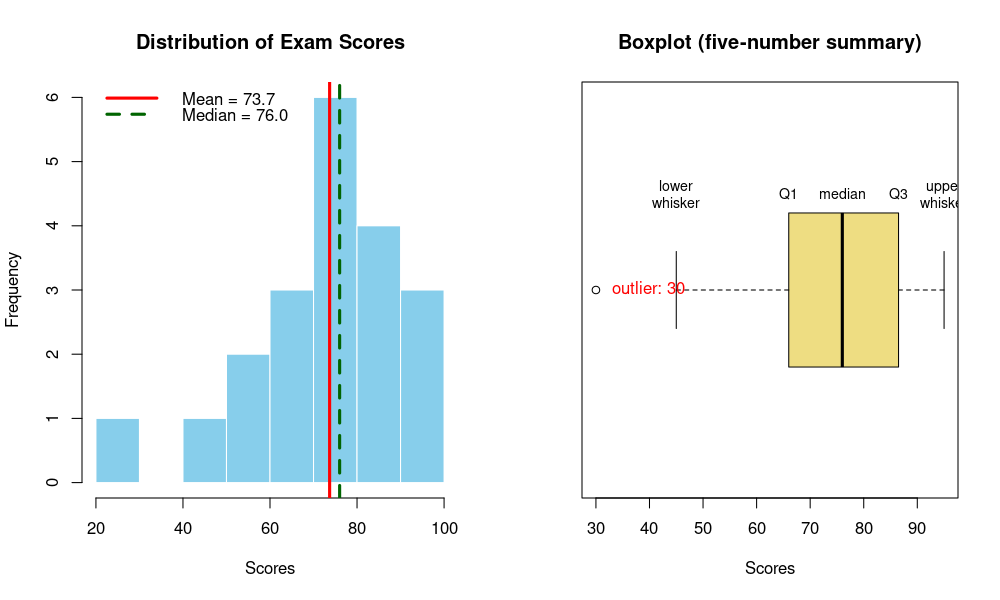

In [4]:
par(mfrow = c(1, 2))
hist(scores, breaks = seq(20, 100, by = 10), col = "skyblue", border = "white",
     main = "Distribution of Exam Scores", xlab = "Scores", ylab = "Frequency")
abline(v = mean(scores), col = "red", lwd = 3)
abline(v = median(scores), col = "darkgreen", lwd = 3, lty = 2)
legend("topleft", legend = c(sprintf("Mean = %.1f", mean(scores)), sprintf("Median = %.1f", median(scores))),
       col = c("red", "darkgreen"), lwd = 3, lty = c(1, 2), bty = "n")

b <- boxplot(scores, col = "lightgoldenrod", horizontal = TRUE, main = "Boxplot (five-number summary)",
             xlab = "Scores")
text(b$stats, rep(1.25, 5), labels = c("lower\nwhisker", "Q1", "median", "Q3", "upper\nwhisker"), cex = 0.85)
if (length(b$out)) text(b$out, 1, labels = paste("outlier:", b$out), pos = 4, col = "red", offset = 0.8)

## 3. Why Spread Matters: Same Mean, Different Story

Two classes can have the **same average** and completely different distributions. Reporting only the mean hides this.

 class mean median   sd   IQR
     A 69.5   69.5  3.8  6.00
     B 70.6   71.0 16.3 30.25


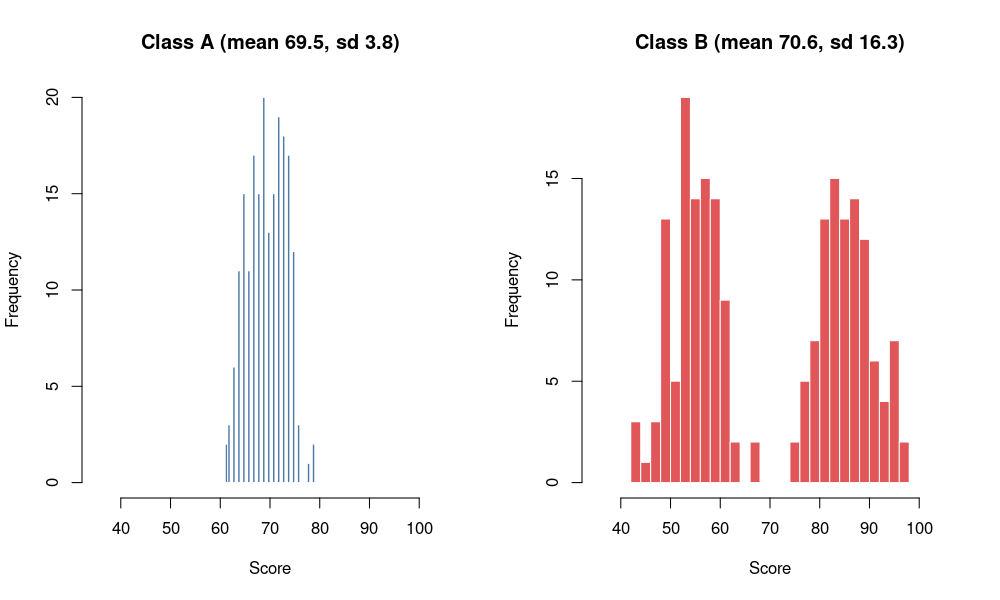

In [5]:
set.seed(10)
class_A <- round(rnorm(200, mean = 70, sd = 4))
class_B <- round(c(rnorm(100, 55, 5), rnorm(100, 85, 5)))

cmp <- data.frame(class = c("A", "B"),
                  mean = c(mean(class_A), mean(class_B)),
                  median = c(median(class_A), median(class_B)),
                  sd = c(sd(class_A), sd(class_B)),
                  IQR = c(IQR(class_A), IQR(class_B)))
print(round_df <- transform(cmp, mean = round(mean, 1), sd = round(sd, 1)), row.names = FALSE)

par(mfrow = c(1, 2))
hist(class_A, breaks = 30, col = "#4E79A7", border = "white", xlim = c(35, 105),
     main = sprintf("Class A (mean %.1f, sd %.1f)", mean(class_A), sd(class_A)), xlab = "Score")
hist(class_B, breaks = 30, col = "#E15759", border = "white", xlim = c(35, 105),
     main = sprintf("Class B (mean %.1f, sd %.1f)", mean(class_B), sd(class_B)), xlab = "Score")

*Insight: Class B is **bimodal**: almost nobody actually scored near its mean of ~70. Always look at the spread and the shape (and ideally a plot) before trusting a single summary number.*

## Real-World Use Case or Analogy

Think of descriptive statistics as a **quick report card** for your data:
- **Mean**: the class's average score.
- **Median**: the middle student's score — the one that doesn't change when a single student bombs the exam.
- **Mode**: the most common score in the class (and sometimes there isn't one!).
- **Spread measures**: how much students' scores differ.

A real estate agent quoting the *average* house price on a street with one mansion is technically correct and practically misleading — the *median* tells buyers what a typical house costs.